# Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd

train=pd.read_csv("../data/case1/train1.csv")
test=pd.read_csv("../data/case1/test1.csv")

for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]

train=train[["n", "Q","P"]]
test=test[["n", "Q","P"]]

In [2]:
def make_features(df):
    features = pd.DataFrame()

    for i in range(4):
        for j in range(4):
            if i == 0 and j == 0:
                continue
            column_name = "n" + str(i) + "Q" + str(j)
            features[column_name] = df["n"] ** i * df["Q"] ** j
    return features

X_train = make_features(train)
y_train = train["P"]

X_test = make_features(test)
y_test = test["P"]


# Forward selection using BIC

Selected: ['n3Q0', 'n2Q1', 'n0Q3', 'n1Q2']  BIC: 2273.306938325188
R² (test): 0.9996292902531838


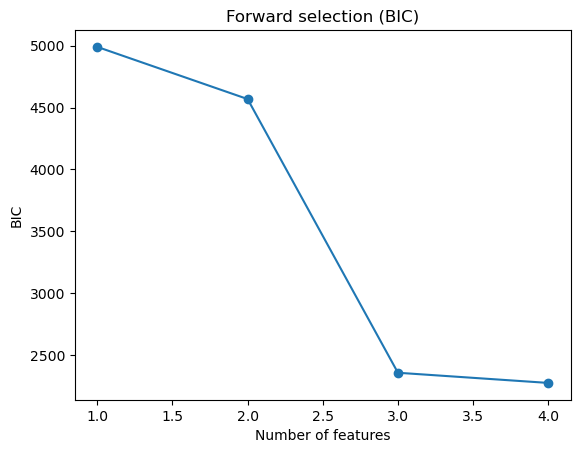

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import numpy as np

def bic(X, y):
    model = LinearRegression().fit(X, y)
    rss = np.sum((y - model.predict(X)) ** 2)
    n = len(y)
    k = X.shape[1] + 1          # +1 for the intercept
    return n * np.log(rss / n) + k * np.log(n) # ignoring constant n*log(2\pi)+n

def forward_bic(X, y):
    n = len(y)
    selected= []
    remaining = list(X.columns)
    history = []
    while remaining:
        scores = {f: bic(X[selected + [f]], y) for f in remaining}
        best = None
        for f in scores:
            if best is None or scores[f] < scores[best]:
                best = f
        if len(history) > 0 and scores[best] >= history[-1]:
            break
        selected.append(best)
        remaining.remove(best)
        history.append(scores[best])
    return selected, history

selected, history = forward_bic(X_train, y_train)
print("Selected:", selected, " BIC:", history[-1])

model = LinearRegression().fit(X_train[selected], y_train)
print("R² (test):", r2_score(y_test, model.predict(X_test[selected])))

plt.plot(range(1, len(history) + 1), history, marker="o")
plt.xlabel("Number of features"); plt.ylabel("BIC"); plt.title("Forward selection (BIC)")
plt.show()

Selected: ['n0Q1', 'n1Q1', 'n1Q2', 'n2Q2', 'n2Q3', 'n3Q0', 'n3Q1', 'n3Q2', 'n3Q3']  BIC: 2300.5155216565663
R² (test): 0.9996191252089163


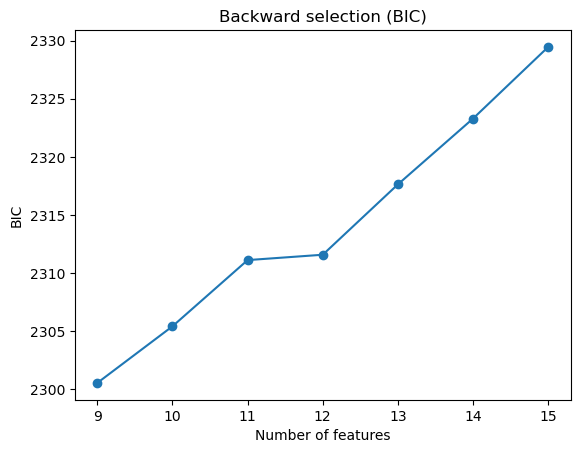

In [ ]:
def backward_bic(X, y):
    selected = list(X.columns)
    history = [bic(X[selected], y)]
    while len(selected) > 1: 
        scores = {f: bic(X[[c for c in selected if c != f]], y) for f in selected}
        best = None
        for f in scores:
            if best is None or scores[f] < scores[best]:
                best = f
        if scores[best] >= history[-1]:
            break
        selected.remove(best)
        history.append(scores[best])
    return selected, history

selected_bwd, history_bwd = backward_bic(X_train, y_train)
print("Selected:", selected_bwd, " BIC:", history_bwd[-1])

model_bwd = LinearRegression().fit(X_train[selected_bwd], y_train)
print("R^2 (test):", r2_score(y_test, model_bwd.predict(X_test[selected_bwd])))

p = X_train.shape[1]
plt.plot(range(p, p - len(history_bwd), -1), history_bwd, marker="o")
plt.xlabel("Number of features"); plt.ylabel("BIC"); plt.title("Backward selection (BIC)")
plt.show()

# Fit model with 4 and 9 terms

In [ ]:

selected_4=['n3Q0', 'n2Q1', 'n0Q3', 'n1Q2'] 
selected_9=['n0Q1', 'n1Q1', 'n1Q2', 'n2Q2', 'n2Q3', 'n3Q0', 'n3Q1', 'n3Q2', 'n3Q3']

final_model_4 = LinearRegression()
final_model_4.fit(X_train[selected_4], y_train)
final_model_9=LinearRegression()
final_model_9.fit(X_train[selected_9], y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [12]:
from sklearn.metrics import mean_squared_error, r2_score

pred_4 = final_model_4.predict(X_test[selected_4])
pred_9 = final_model_9.predict(X_test[selected_9])

print("4 features: MSE =", mean_squared_error(y_test, pred_4), " R² =", r2_score(y_test, pred_4))
print("9 features: MSE =", mean_squared_error(y_test, pred_9), " R² =", r2_score(y_test, pred_9))

4 features: MSE = 107.3021512353302  R² = 0.9996292902531838
9 features: MSE = 110.24442919450969  R² = 0.9996191252089163


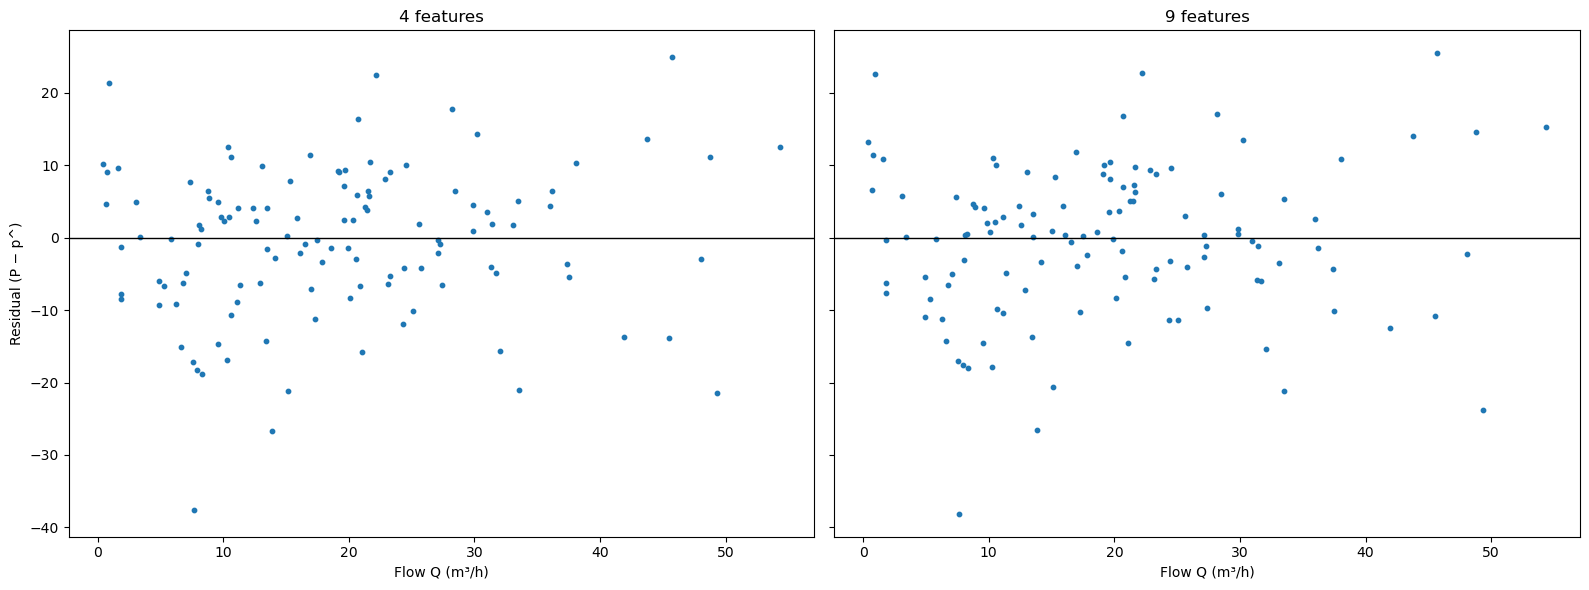

In [15]:
res_4 = y_test - pred_4
res_9 = y_test - pred_9
Q = X_test["n0Q1"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

axes[0].scatter(Q, res_4, s=10)
axes[0].set_title("4 features")

axes[1].scatter(Q, res_9, s=10)
axes[1].set_title("9 features")

for ax in axes:
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xlabel("Flow Q (m³/h)")
axes[0].set_ylabel("Residual (P − p^)")

plt.tight_layout()
plt.show()